# Phase 4: what the archetypes look like, and how soft they are

Reads `reports/p4/*.json` and `artifacts/p4/` (written by `cluster.py` and `diagnostics.py`). Train rows only.
Reading rule (D-047): the groups are **bins on a continuum**; only clusters with mean Jaccard >= 0.6 may be described, and only as "tends to be".

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cricmind import config
from cricmind.archetypes import vectors as vec

REP = config.REPORTS / "p4"
ART = config.ARTIFACTS / "p4"
clusters = json.loads((REP / "clusters.json").read_text())["cells"]
profiles = json.loads((REP / "profiles.json").read_text())
diag = json.loads((REP / "diagnostics.json").read_text())
CELLS = ["stats_batter", "stats_bowler", "emb_batter", "emb_bowler"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Is there structure? Stability and silhouette by k
Bootstrap ARI never reaches the 0.6 gate for any k, and silhouette stays under 0.25 ("no substantial structure"). The embedding arm sits at zero.

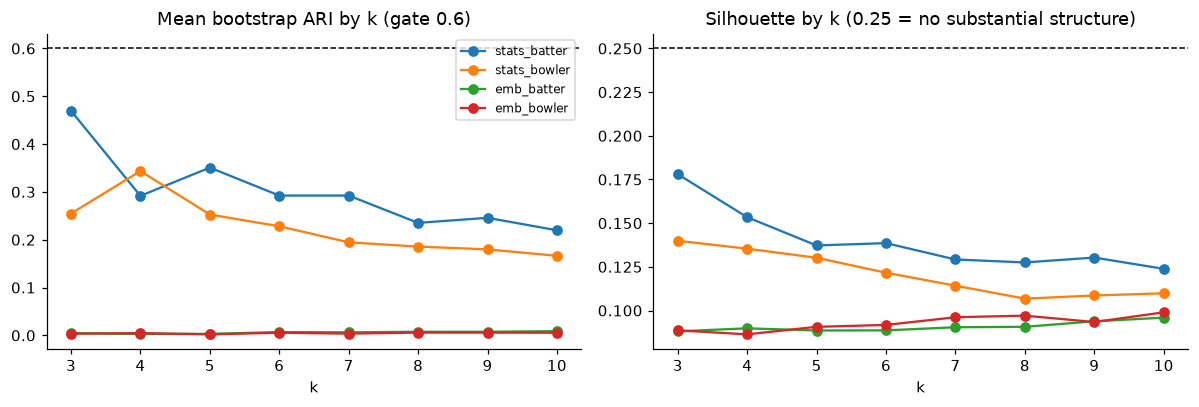

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for key in CELLS:
    c = clusters[key]
    t = pd.DataFrame(c["tables"][f"{c['min_balls']}_{'pca' if c['pca'] else 'raw'}"])
    ax[0].plot(t["k"], t["boot_ari_mean"], marker="o", label=key)
    ax[1].plot(t["k"], t["silhouette"], marker="o", label=key)
ax[0].axhline(0.6, ls="--", c="k", lw=1)
ax[0].set_title("Mean bootstrap ARI by k (gate 0.6)")
ax[1].axhline(0.25, ls="--", c="k", lw=1)
ax[1].set_title("Silhouette by k (0.25 = no substantial structure)")
for a in ax:
    a.set_xlabel("k")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. The players in 2-D (stats arm)
First two principal components of the standardised stats vector, coloured by bin. Look for gaps between colours: there are none, the colours tile one cloud.

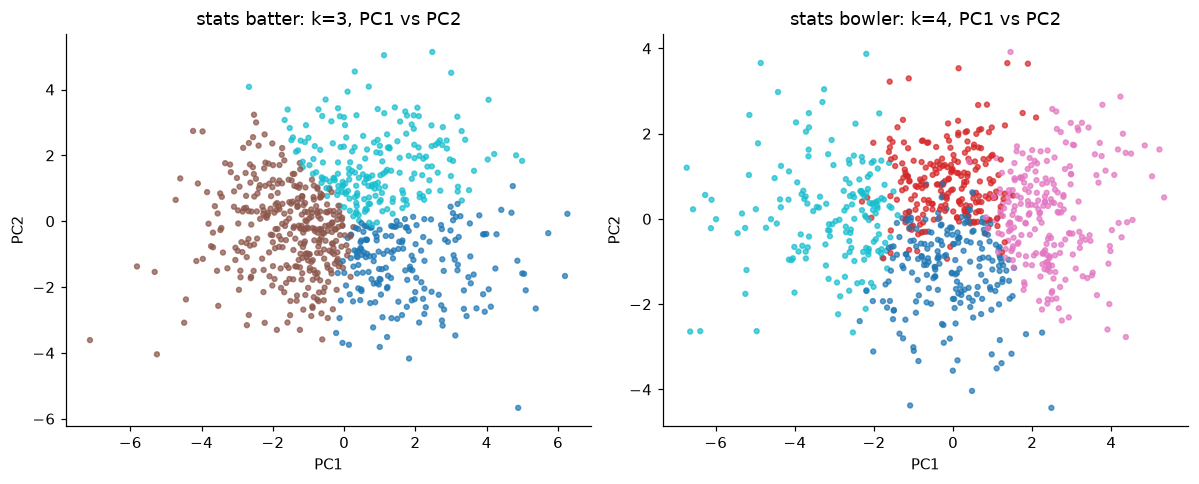

In [3]:
train, _ = vec.load_train()  # train rows only; takes a moment
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    c = clusters["stats_" + role]
    ids = vec.eligibility(train, role, c["min_balls"]).index
    X = vec.stats_vectors(train, role, ids).to_numpy()
    model = joblib.load(ART / f"kmeans_stats_{role}.joblib")
    Z = model[:-1].transform(X)  # scaler + PCA (the chosen cells use PCA 90%), so columns are PC1, PC2, ...
    a.scatter(Z[:, 0], Z[:, 1], c=model[-1].labels_, cmap="tab10", s=10, alpha=0.7)
    a.set_title(f"stats {role}: k={c['k']}, PC1 vs PC2")
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 3. What each bin is (z-score of each stat against all eligible players)
Red = above the population, blue = below. Names are only allowed for bins in section 4 with mean Jaccard >= 0.6.

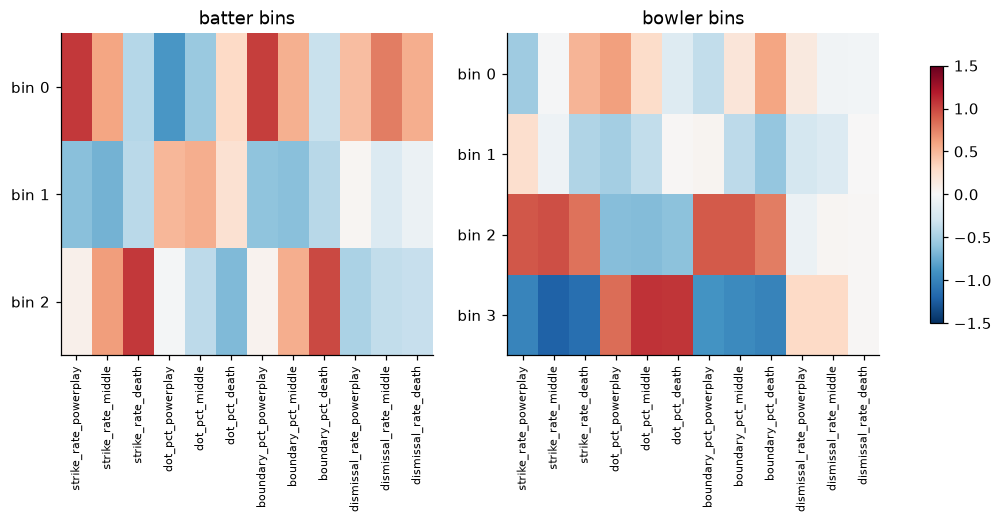

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    z = pd.DataFrame({p["cluster"]: p["z_stats"] for p in profiles["stats_" + role]}).T
    im = a.imshow(z.to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    a.set_xticks(range(z.shape[1]), z.columns, rotation=90, fontsize=7)
    a.set_yticks(range(len(z)), [f"bin {i}" for i in z.index])
    a.set_title(f"{role} bins")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 4. Which bins survive resampling? (clusterwise Jaccard, D-046/D-047)
Green = mean Jaccard >= 0.6 (may be described). Dashed lines: 0.5 dissolved, 0.6 pattern, 0.75 stable.

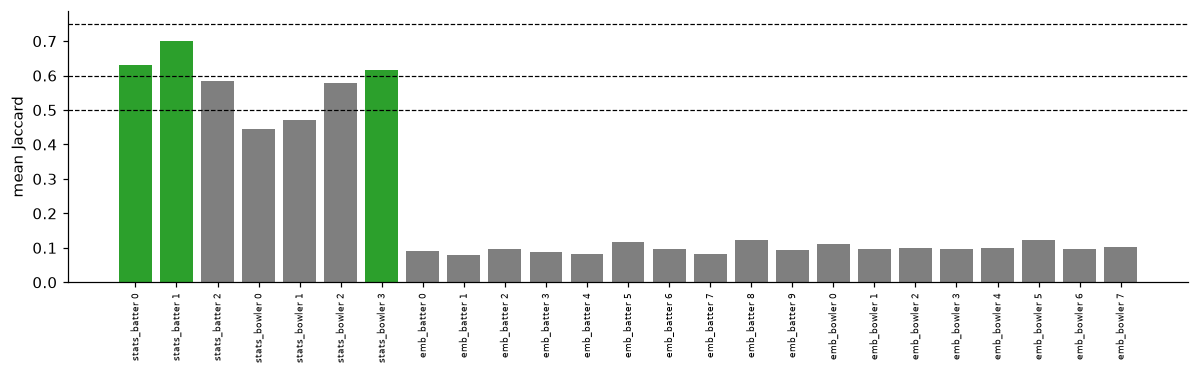

In [5]:
d = pd.DataFrame(
    [
        dict(cell=k, cluster=c["cluster"], j=c["mean_jaccard"])
        for k, cs in diag["clusterwise"].items()
        for c in cs
    ]
)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(len(d)), d["j"], color=np.where(d["j"] >= 0.6, "tab:green", "tab:gray"))
for y in (0.5, 0.6, 0.75):
    ax.axhline(y, ls="--", c="k", lw=0.8)
ax.set_xticks(range(len(d)), d["cell"] + " " + d["cluster"].astype(str), rotation=90, fontsize=6)
ax.set_ylabel("mean Jaccard")
plt.tight_layout()
plt.show()

## 5. How soft are the boundaries? (GMM membership probability)
A GMM fitted at the same k gives each player a probability of belonging to their best bin. A pile at 1.0 would mean clean groups; mass below 0.9 means many players sit between bins.

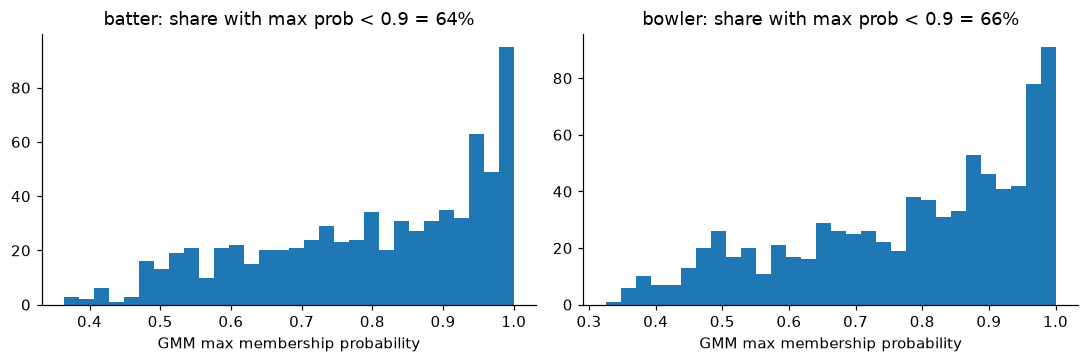

In [6]:
arch = pd.read_parquet(ART / "archetypes_stats.parquet")
g = arch[arch["method"] == "gmm"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, role in zip(ax, ["batter", "bowler"], strict=True):
    p = g.loc[g["role"] == role, "prob"]
    a.hist(p, bins=30)
    a.set_title(f"{role}: share with max prob < 0.9 = {100 * (p < 0.9).mean():.0f}%")
    a.set_xlabel("GMM max membership probability")
plt.tight_layout()
plt.show()

## 6. Same data, different starts (seeding experiment)
Relative spread of final inertia over 50 single starts. Small = k-means finds the same optimum from any start, so the instability in section 1 comes from resampling the data, not from the algorithm.

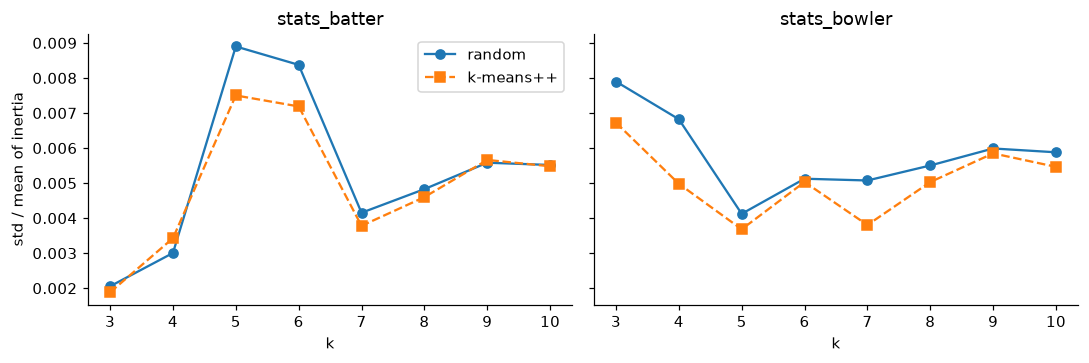

In [7]:
seed = json.loads((REP / "seeding.json").read_text())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, key in zip(ax, ["stats_batter", "stats_bowler"], strict=True):
    for init, style in (("random", "o-"), ("k-means++", "s--")):
        ks = sorted(seed[key][init], key=int)
        s = seed[key][init]
        rel = [s[k]["inertia_std"] / s[k]["inertia_mean"] for k in ks]
        a.plot([int(k) for k in ks], rel, style, label=init)
    a.set_title(key)
    a.set_xlabel("k")
ax[0].set_ylabel("std / mean of inertia")
ax[0].legend()
plt.tight_layout()
plt.show()

## Reading
- Sections 1, 2 and 5: no gaps, soft boundaries, silhouette under 0.25: a continuum cut into bins.
- Section 6: the algorithm is repeatable, so the instability is a property of the data (D-047).
- Section 4: at most three bins (batter 0 and 1, bowler 3) may be called "tends to be ..."; everything else is a bin.
- Whether the bins are useful is a Phase 5 question (held-out log-loss), not a Phase 4 one.